# NB25 — Heteroscedasticity Fixes: Robust SEs, WLS and HAC

> **StatQuest principle: when the spread of the residuals changes, the line is still fine — it's the error bars that lie.**

---

## The main ideas are:

1. **Heteroscedasticity** = the variance of the residuals changes with x (a "funnel" in the residual plot)
2. OLS **coefficients stay unbiased**, but the classic standard errors, p-values and confidence intervals are **wrong**
3. **Detect** it: residual plot + Breusch–Pagan test (+ White test)
4. **Fix #1 — robust (HC3) standard errors:** same coefficients, honest uncertainty
5. **Fix #2 — Weighted Least Squares (WLS):** weight each point by 1/σᵢ² → more *efficient* (less noisy) estimates
6. **Autocorrelated errors** (time order) break SEs too → **HAC / Newey–West** standard errors

NB06 showed how to *diagnose* unequal variance. This notebook shows what to *do* about it.


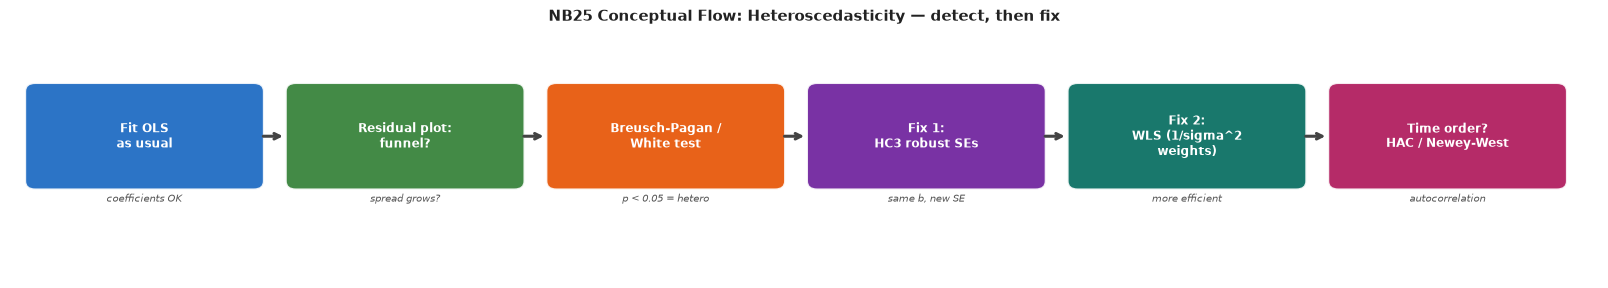

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=['Fit OLS\nas usual', 'Residual plot:\nfunnel?', 'Breusch-Pagan /\nWhite test', 'Fix 1:\nHC3 robust SEs',
           'Fix 2:\nWLS (1/sigma^2\nweights)', 'Time order?\nHAC / Newey-West'],
    title='NB25 Conceptual Flow: Heteroscedasticity — detect, then fix',
    notes=['coefficients OK', 'spread grows?', 'p < 0.05 = hetero', 'same b, new SE', 'more efficient', 'autocorrelation'],
    figsize=(16, 2.8),
)


## Step 1 — Detect: residual plot + Breusch–Pagan + White

Data: the noise standard deviation grows with x:  σᵢ = 0.3 + 0.5·xᵢ, true line y = 3 + 2x.

- **Breusch–Pagan:** regress the squared residuals on X. If X explains them → variance depends on X.
- **White test:** same idea, but also uses squares and cross-products of X (catches non-linear variance patterns).
- H0 for both: *constant variance* (homoscedasticity). Small p-value → reject H0.


OLS fit: y = 3.0411 + 1.9976 x   (true: 3 + 2x)
Breusch-Pagan: LM = 23.21, p = 1.45e-06
White test   : LM = 23.62, p = 7.45e-06
-> p < 0.05: reject constant variance. Heteroscedasticity confirmed.


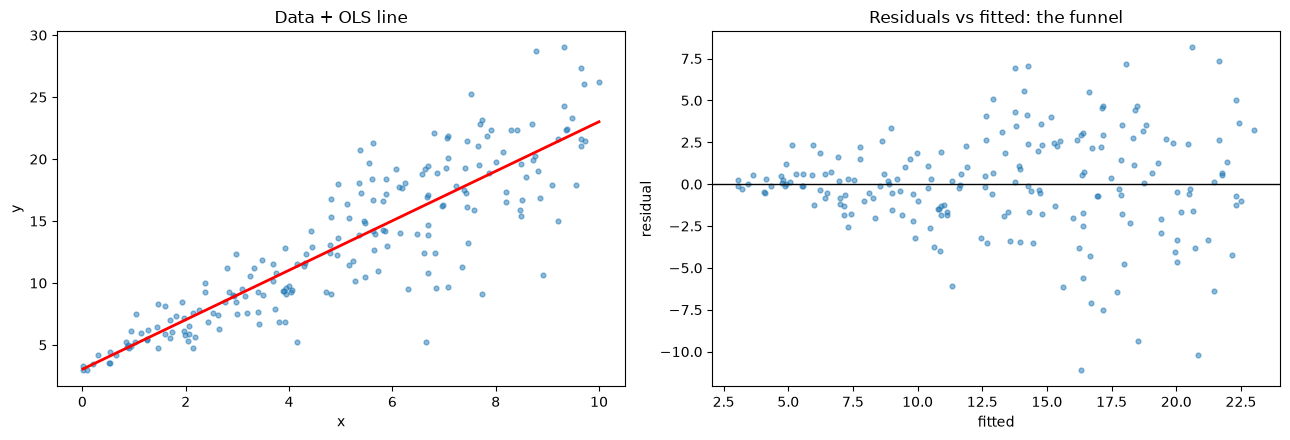

In [2]:
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
import matplotlib.pyplot as plt

rng   = np.random.default_rng(3)
n     = 200
x     = rng.uniform(0, 10, n)
sigma = 0.3 + 0.5 * x                      # true noise SD grows with x
y     = 3 + 2 * x + rng.normal(0, sigma)
X     = sm.add_constant(x)

ols = sm.OLS(y, X).fit()
bp_lm, bp_p, _, _ = het_breuschpagan(ols.resid, X)
w_lm,  w_p,  _, _ = het_white(ols.resid, X)

print(f"OLS fit: y = {ols.params[0]:.4f} + {ols.params[1]:.4f} x   (true: 3 + 2x)")
print(f"Breusch-Pagan: LM = {bp_lm:.2f}, p = {bp_p:.2e}")
print(f"White test   : LM = {w_lm:.2f}, p = {w_p:.2e}")
print("-> p < 0.05: reject constant variance. Heteroscedasticity confirmed.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(x, y, s=12, alpha=0.5); ax[0].plot(np.sort(x), ols.params[0] + ols.params[1]*np.sort(x), 'r', lw=2)
ax[0].set_title('Data + OLS line'); ax[0].set_xlabel('x'); ax[0].set_ylabel('y')
ax[1].scatter(ols.fittedvalues, ols.resid, s=12, alpha=0.5); ax[1].axhline(0, color='k', lw=1)
ax[1].set_title('Residuals vs fitted: the funnel'); ax[1].set_xlabel('fitted'); ax[1].set_ylabel('residual')
plt.tight_layout(); plt.show()


## Step 2 — Fix #1: robust (heteroscedasticity-consistent) standard errors

The classic formula Var(b) = σ²(XᵀX)⁻¹ assumes **one** σ² for every point.
The **sandwich** estimator drops that assumption:

```
Var(b) = (XᵀX)⁻¹ · [ Σ wᵢ eᵢ² xᵢxᵢᵀ ] · (XᵀX)⁻¹        HC3: wᵢ = 1/(1 − hᵢᵢ)²
```

HC3 inflates residuals of high-leverage points (hᵢᵢ = hat-matrix diagonal) and is the recommended default for small/medium n.

**Key point:** the coefficients are *identical* — only SEs, t, p and CIs change.

In a **single** sample the robust SE can come out larger *or* smaller than the classic one — robust SEs are themselves noisy estimates.
What matters is their behaviour **on average**, which the coverage simulation below checks.


In [3]:
hc3 = sm.OLS(y, X).fit(cov_type='HC3')

print(f"{'':10s}{'coef':>9s}{'classic SE':>12s}{'HC3 SE':>10s}{'classic 95% CI':>22s}{'HC3 95% CI':>22s}")
for i, name in enumerate(['const', 'x']):
    c_lo, c_hi = ols.conf_int()[i]
    h_lo, h_hi = hc3.conf_int()[i]
    print(f"{name:10s}{ols.params[i]:9.4f}{ols.bse[i]:12.4f}{hc3.bse[i]:10.4f}"
          f"   [{c_lo:7.4f}, {c_hi:7.4f}]   [{h_lo:7.4f}, {h_hi:7.4f}]")
print(f"\nSame coefficients? {np.allclose(ols.params, hc3.params)}")
print(f"HC3 / classic SE  slope: {hc3.bse[1]/ols.bse[1]:.3f}   intercept: {hc3.bse[0]/ols.bse[0]:.3f}")
print("In this sample the HC3 slope SE happens to be a bit smaller; the intercept SE is much smaller.")
print("Classic SEs spread ONE average sigma^2 over all points, so they misstate uncertainty where noise is low or high.")


               coef  classic SE    HC3 SE        classic 95% CI            HC3 95% CI
const        3.0411      0.4562    0.2813   [ 2.1414,  3.9407]   [ 2.4898,  3.5923]
x            1.9976      0.0795    0.0751   [ 1.8409,  2.1543]   [ 1.8504,  2.1449]

Same coefficients? True
HC3 / classic SE  slope: 0.945   intercept: 0.617
In this sample the HC3 slope SE happens to be a bit smaller; the intercept SE is much smaller.
Classic SEs spread ONE average sigma^2 over all points, so they misstate uncertainty where noise is low or high.


### Does it matter? A coverage simulation

A correct 95% confidence interval should contain the true slope (2.0) in **95%** of repeated samples.
We repeat the experiment 2,000 times and count.


In [4]:
def one_sample(rng, n=200):
    x = rng.uniform(0, 10, n)
    y = 3 + 2 * x + rng.normal(0, 0.3 + 0.5 * x)
    return x, y

rng_sim = np.random.default_rng(2024)
reps = 2000
cover_classic = cover_hc3 = 0
for _ in range(reps):
    xs, ys = one_sample(rng_sim)
    Xs = sm.add_constant(xs)
    lo, hi = sm.OLS(ys, Xs).fit().conf_int()[1]
    cover_classic += lo <= 2 <= hi
    lo, hi = sm.OLS(ys, Xs).fit(cov_type='HC3').conf_int()[1]
    cover_hc3 += lo <= 2 <= hi

print(f"95% CI coverage of the true slope over {reps} samples:")
print(f"  classic SEs : {cover_classic/reps:.1%}")
print(f"  HC3 SEs     : {cover_hc3/reps:.1%}")
print("-> on average the classic slope intervals are too narrow: they claim 95% but cover less; HC3 is on target.")


95% CI coverage of the true slope over 2000 samples:
  classic SEs : 93.4%
  HC3 SEs     : 95.3%
-> on average the classic slope intervals are too narrow: they claim 95% but cover less; HC3 is on target.


## Step 3 — Fix #2: Weighted Least Squares (WLS)

Robust SEs fix the *error bars*. WLS goes further and fixes the *estimate itself*:
noisy points get **less say**, precise points get **more**.

```
minimise  Σ wᵢ (yᵢ − b0 − b1·xᵢ)²       with  wᵢ = 1 / σᵢ²
```

Under the right weights WLS is the **Best Linear Unbiased Estimator** (Gauss–Markov holds again after reweighting).

In practice σᵢ is unknown → **Feasible WLS**: model the variance from the OLS residuals
(here: regress log(eᵢ²) on x, then wᵢ = 1 / exp(fitted)).


In [5]:
# Known weights
wls_known = sm.WLS(y, X, weights=1 / sigma**2).fit()

# Feasible WLS: estimate the variance function from OLS residuals
aux       = sm.OLS(np.log(ols.resid**2), X).fit()
w_hat     = 1 / np.exp(aux.fittedvalues)
wls_feas  = sm.WLS(y, X, weights=w_hat).fit()

for name, r in [('OLS', ols), ('WLS (known sigma)', wls_known), ('Feasible WLS', wls_feas)]:
    print(f"{name:18s} slope = {r.params[1]:.4f}   SE = {r.bse[1]:.4f}")


OLS                slope = 1.9976   SE = 0.0795
WLS (known sigma)  slope = 1.9805   SE = 0.0508
Feasible WLS       slope = 1.9709   SE = 0.0635


Slope estimates over 2000 samples (true = 2.0):
  OLS           mean = 2.0011   SD = 0.0833
  WLS known     mean = 2.0016   SD = 0.0513
  Feasible WLS  mean = 2.0020   SD = 0.0553

Variance ratio OLS / WLS(known): 2.64x
-> all three are unbiased; WLS is noticeably more precise.


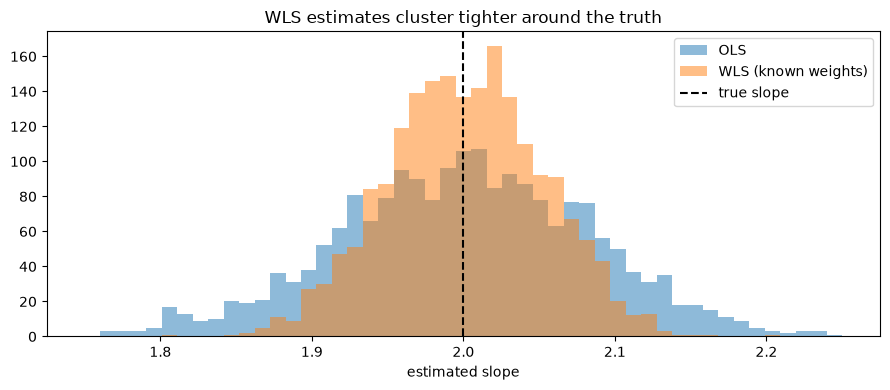

In [6]:
# Efficiency: how much do the slope estimates scatter across repeated samples?
rng_sim = np.random.default_rng(7)
b_ols, b_wls, b_fwls = [], [], []
for _ in range(2000):
    xs = rng_sim.uniform(0, 10, 200); sd = 0.3 + 0.5 * xs
    ys = 3 + 2 * xs + rng_sim.normal(0, sd)
    Xs = sm.add_constant(xs)
    o  = sm.OLS(ys, Xs).fit()
    b_ols.append(o.params[1])
    b_wls.append(sm.WLS(ys, Xs, weights=1/sd**2).fit().params[1])
    a  = sm.OLS(np.log(o.resid**2), Xs).fit()
    b_fwls.append(sm.WLS(ys, Xs, weights=1/np.exp(a.fittedvalues)).fit().params[1])

b_ols, b_wls, b_fwls = map(np.array, (b_ols, b_wls, b_fwls))
print("Slope estimates over 2000 samples (true = 2.0):")
for name, b in [('OLS', b_ols), ('WLS known', b_wls), ('Feasible WLS', b_fwls)]:
    print(f"  {name:13s} mean = {b.mean():.4f}   SD = {b.std():.4f}")
print(f"\nVariance ratio OLS / WLS(known): {b_ols.var()/b_wls.var():.2f}x")
print("-> all three are unbiased; WLS is noticeably more precise.")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(1.75, 2.25, 50)
ax.hist(b_ols, bins, alpha=0.5, label='OLS'); ax.hist(b_wls, bins, alpha=0.5, label='WLS (known weights)')
ax.axvline(2, color='k', ls='--', label='true slope')
ax.set_title('WLS estimates cluster tighter around the truth'); ax.set_xlabel('estimated slope'); ax.legend()
plt.tight_layout(); plt.show()


## Step 4 — Autocorrelated errors: HAC (Newey–West) standard errors

With time-ordered data the errors are often **correlated** with their neighbours (NB06: Durbin–Watson far from 2).
Again the coefficients are unbiased, but classic SEs are typically **too small** when both x and the errors are positively autocorrelated.

**HAC** (heteroscedasticity- and autocorrelation-consistent, Newey–West) SEs account for correlation up to `maxlags` lags.
Rule of thumb: maxlags ≈ 4·(n/100)^(2/9).


In [7]:
from statsmodels.stats.stattools import durbin_watson

rng = np.random.default_rng(0)
n   = 200
def ar1(rho, sd, n, rng):
    e = np.zeros(n)
    for t in range(1, n):
        e[t] = rho * e[t-1] + rng.normal(0, sd)
    return e
xt = ar1(0.8, 1.0, n, rng)               # a slowly moving predictor
et = ar1(0.8, 1.0, n, rng)               # autocorrelated errors
yt = 1 + 0.5 * xt + et
Xt = sm.add_constant(xt)

maxlags = int(np.floor(4 * (n / 100) ** (2 / 9)))
classic = sm.OLS(yt, Xt).fit()
hac     = sm.OLS(yt, Xt).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})

print(f"Durbin-Watson = {durbin_watson(classic.resid):.3f}   (2 = no autocorrelation)")
print(f"maxlags = {maxlags}")
print(f"slope = {classic.params[1]:.4f}")
print(f"  classic SE = {classic.bse[1]:.4f}   p = {classic.pvalues[1]:.2e}")
print(f"  HAC SE     = {hac.bse[1]:.4f}   p = {hac.pvalues[1]:.2e}")
print(f"HAC / classic SE: {hac.bse[1]/classic.bse[1]:.2f}x")


Durbin-Watson = 0.586   (2 = no autocorrelation)
maxlags = 4
slope = 0.3541
  classic SE = 0.0606   p = 2.06e-08
  HAC SE     = 0.1149   p = 2.05e-03
HAC / classic SE: 1.90x


## Key Takeaways

| Problem | Coefficients | Classic SEs | Fix |
|---|---|---|---|
| Heteroscedasticity | unbiased | wrong (here: too small) | **HC3 robust SEs** (always safe) or **WLS** (more efficient if you can model σᵢ) |
| Autocorrelation | unbiased | wrong (usually too small) | **HAC / Newey–West SEs**, or model the time structure (NB19) |
| Non-linearity | **biased** | — | Fix the model (NB10, NB26), not the SEs |

1. Heteroscedasticity does **not** bias OLS coefficients — it breaks their **uncertainty**.
2. `fit(cov_type='HC3')` is a one-line fix that keeps the coefficients and corrects SEs, p-values and CIs.
3. WLS with weights 1/σᵢ² is **BLUE** again → tighter estimates; Feasible WLS estimates the weights from residuals.
4. For time-ordered data use `cov_type='HAC'`.
5. Robust SEs are not a cure for a **wrong model**: if the residual plot curves, change the model.
